In [375]:
cd ~/PycharmProjects/CleanSpace/momia2/

/Users/jzrolling/PycharmProjects/CleanSpace/momia2


In [132]:
import momia2 as mo
from dtw import dtw
import os, glob, pandas as pd, numpy as np
import tifffile
from matplotlib import pyplot as plt
from scipy.stats import pearsonr
from IPython.display import display,clear_output
from joblib import Parallel, delayed
from skimage.registration import phase_cross_correlation
import seaborn as sns
from umap import UMAP
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.



In [376]:
sample_reference = pd.read_excel('/Volumes/ExtremePro/PMM_FTSZ_RAW/sample_reference.xlsx')
include = sample_reference[sample_reference['Include for analysis']==1].copy()

batch_dict = {}
for f in sorted(glob.glob('/Volumes/ExtremePro/PMM_FTSZ_RAW/BCG_FtsZ*/')):
    batch = f.split('/')[-2]
    if batch not in batch_dict:
        batch_dict[batch] = {}
    for seg_file in sorted(glob.glob(f+'*.pk')):
        if 'autosave__' in seg_file:
            well = seg_file.split('autosave__')[-1].split('_')[0]
        elif 'autosave' in seg_file:
            well = seg_file.split('autosave_')[-1].split('_')[0]
        else:
            well = seg_file.split('Well-')[-1].split('_')[0]
        
        if len(well)!=3:
            continue
        img_file = seg_file.replace('_seg.pk','.tif')
        if well not in batch_dict[batch]:
            batch_dict[batch][well] = [[img_file,seg_file]]
        else:
            batch_dict[batch][well] += [[img_file,seg_file]]

inshade_cols = ['InShaDe_{}'.format(x) for x in range(1,33)]
fl_val_cols = ['log2_C{}_{}'.format(c,s) for c in range(1,5) for s in ['mean','median','max','min','Q1','Q3']]
fl_stat_cols = ['C{}_{}'.format(c,s) for c in range(1,5) for s in ['CV','kurtosis','skewness']] + ['C4-C2_diff']
morph_cols = ['area','eccentricity','solidity','major_axis_length','minor_axis_length','extent',
              'moments_hu-0','moments_hu-1','moments_hu-2','moments_hu-3',
              'moments_hu-4','moments_hu-5','moments_hu-6','compactness','aspect_ratio','min_negative_curvature','max_positive_curvature','mean_curvature',
              'Q1_curvature','Q3_curvature','length [µm]','branched',
              'width_median [µm]','width_std [µm]','width_max [µm]','width_Q1 [µm]','width_Q3 [µm]',]

num_feature_cols = morph_cols + fl_val_cols
stat_feature_cols = inshade_cols + fl_stat_cols
all_feature_cols = num_feature_cols + stat_feature_cols
grouped_feature_cols = ['{}_{}'.format(c,feature) for c in ['MEAN','MEDIAN','SKEW','IQR','CV','Q1','Q3'] for feature in all_feature_cols ]+['Group_count']


In [425]:
merged_grouped = mo.pickle_load('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/20260901_batchnorm_merged_grouped.pk')
test_compounds = pd.read_excel('/Users/jzrolling/Desktop/Projects/GHDDI/BCG_BCP/test_compounds.xlsx')

In [781]:
anchor_compounds = ['Capreomycin',
                    'CIP','MXF',
                    'SQ109','Clarithromycin','Linzolid','Amikacin',
                    'Amikacin','Tobramycin','Azithromycin','Gentamycin',
                    'SBZ-6B','BTZ-043','Tigecycline']
cell_division_compounds = [x for x in test_compounds['Src_ID'].values if x not in ['na','GSK20','GDI-B029']]
ftsz = ['GH161-96hrs-Rep1','GH161-96hrs-Rep2']

In [894]:
anchor = merged_grouped[merged_grouped['Compound'].isin(anchor_compounds+cell_division_compounds+ftsz)].copy()
rif = merged_grouped[(merged_grouped['Compound']=='RIF')&(merged_grouped['Batch']!='BCG_FtsZ_HT_Plate02_Batch04_20250519')].copy()
inh = merged_grouped[(merged_grouped['Compound']=='INH')&(merged_grouped['Batch']!='BCG_FtsZ_HT_Plate02_Batch04_20250519')].copy()
gsk20 = merged_grouped[(merged_grouped['Compound']=='GSK20')&(merged_grouped['Batch']!='BCG_FtsZ_HT_Plate0708_Batch02_20250528')].copy()
gdib029 = merged_grouped[(merged_grouped['Compound']=='GDI-B029')&(merged_grouped['Batch']!='BCG_FtsZ_HT_Plate04_Batch03_20250520')].copy()
anchor = pd.concat([anchor,rif,gsk20,gdib029,inh])
anchor = anchor[anchor['Sample_UID']!='BCG_FtsZ_HT_Plate06_Batch03_20250527_D03'].copy().reset_index(drop=True)

/Users/jzrolling/miniconda3/envs/tensorflow_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


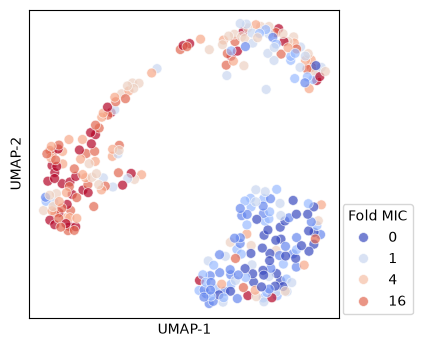

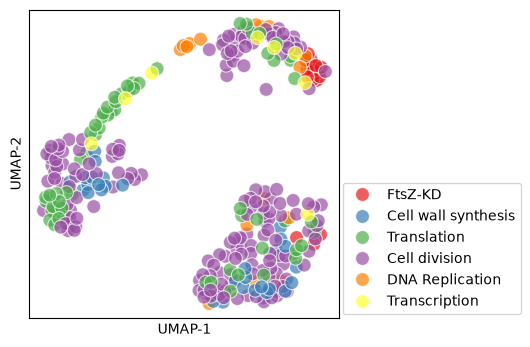

In [1051]:
inshade_cols = ['InShaDe_{}'.format(x) for x in range(1,33)]
fl_val_cols = ['log2_C{}_{}'.format(c,s) for c in range(1,5) for s in ['mean','Q1','Q3']]
fl_stat_cols = ['C4-C2_diff'] + ['C{}_{}'.format(c,s) for c in range(1,5) for s in ['CV','kurtosis']] 
morph_cols = ['area','length [µm]','width_median [µm]','width_std [µm]']

num_feature_cols = morph_cols + fl_val_cols
stat_feature_cols = inshade_cols + fl_stat_cols
all_feature_cols = num_feature_cols + stat_feature_cols 
grouped_feature_cols = ['{}_{}'.format(c,feature) for c in ['MEAN','CV','IQR'] for feature in all_feature_cols]

vals = anchor[grouped_feature_cols].values.astype(float)
isnan_ids = np.unique(np.where(np.isnan(vals))[1])
isinf_ids = np.unique(np.where(np.isinf(vals))[1])
valid_cols = np.array([x for x in range(vals.shape[1]) if x not in np.hstack([isnan_ids,isinf_ids])])
vals_filtered = vals[:, valid_cols]

norm = StandardScaler().fit_transform(vals_filtered)
pc = PCA(n_components=2).fit_transform(norm)


n_components = 2
umap = UMAP(n_components=n_components, n_jobs=-1, n_neighbors=40,
            min_dist=0.001,
            metric='cosine',random_state=42,spread=12)
u = umap.fit_transform(norm)

anchor[['PC1','PC2']] = pc
anchor[[f'UMAP-{x+1}' for x in range(n_components)]] =u

fig=plt.figure(figsize=(4,4))
ax=fig.add_subplot()
sns.scatterplot(data=anchor[~anchor['Group'].isin(['FtsZ-Ctrl'])],s=50,alpha=0.7,
                x='UMAP-1',y='UMAP-2',hue='log_Fold_mic',palette='coolwarm')    
legend = ax.legend(loc=(-0.01,0.6))
handles, labels = ax.get_legend_handles_labels()
keep_indices = [i for i in [0,2,3,4]]  
ax.legend(selected_handles, [0,1,4,16], loc=(1.01,0.01), title='Fold MIC')
ax.set_xticks([])
ax.set_yticks([])
plt.savefig('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/umap_fold_mic.svg',bbox_inches='tight')

fig=plt.figure(figsize=(4,4))
ax=fig.add_subplot()
sns.scatterplot(data=anchor[(~anchor['Group'].isin(['FtsZ-Ctrl']))],s=100,alpha=0.7,
                x='UMAP-1',y='UMAP-2',hue='Group',palette='Set1')  
ax.set_xticks([])
ax.set_yticks([])
ax.legend(loc=(1.01,0.01))
plt.savefig('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/umap_grouped_small.svg',bbox_inches='tight')

In [922]:
compound_abr = {'GH161-96hrs-Rep1':'FtsZ-KD',
                'GH161-96hrs-Rep2':'FtsZ-KD',
                'Clarithromycin':'CLA','Tigecycline':'TGC',
                'Linzolid':'LZD','Amikacin':'AMK','Tobramycin':'TOB',
                'Capreomycin':'CAP','Azithromycin':'AZM','Gentamycin':'GEN'}

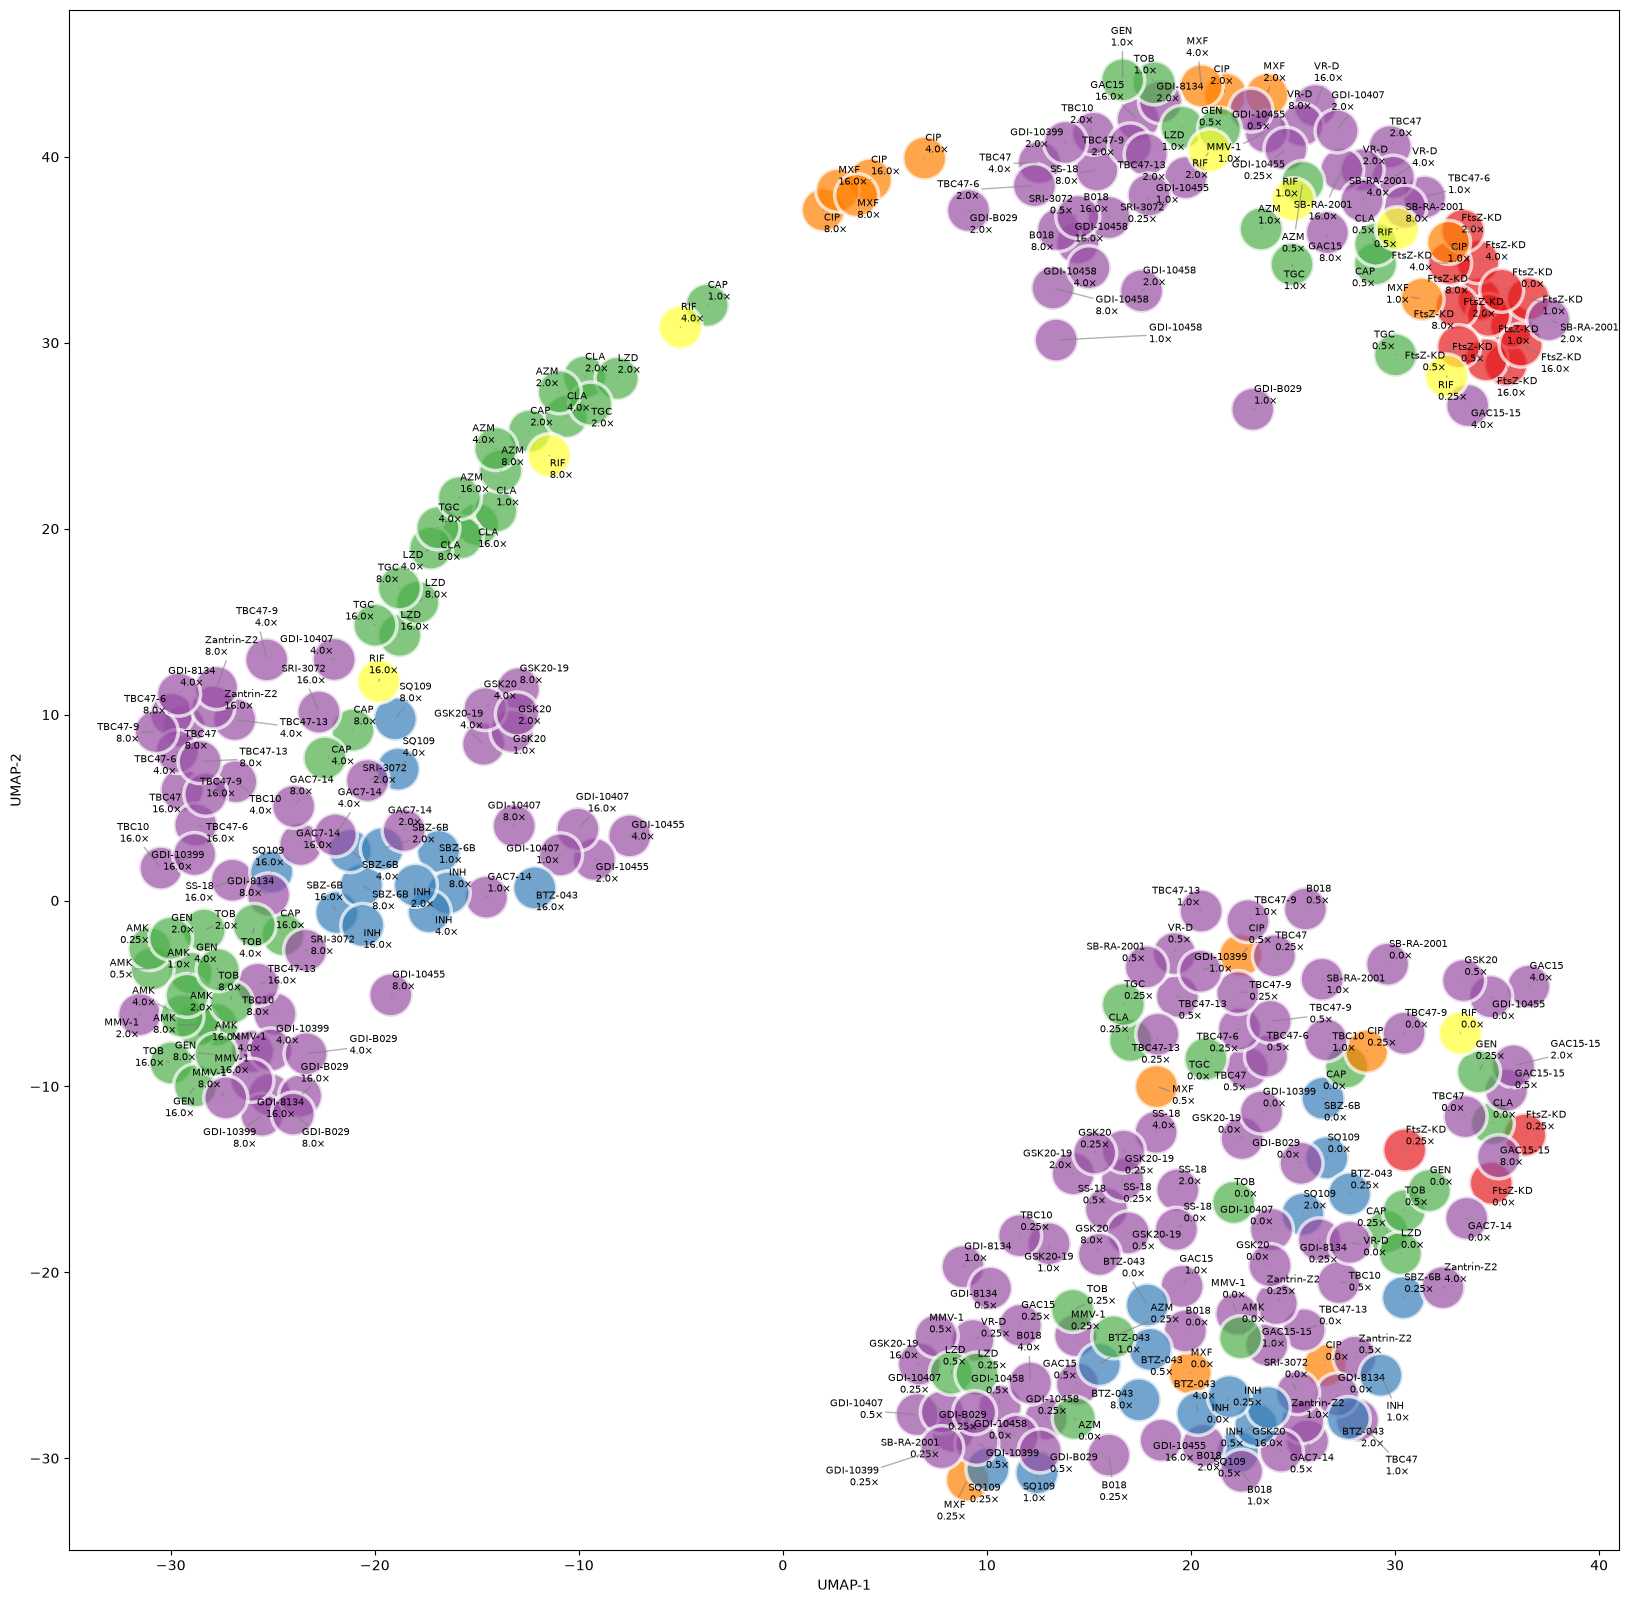

In [946]:
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text

fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot()
selected = anchor[(~anchor['Group'].isin(['FtsZ-Ctrl']))].copy()

sns.scatterplot(data=selected, s=1000, alpha=0.7, x='UMAP-1', y='UMAP-2', hue='Group', palette='Set1',legend=False)
texts = []
for x, y, cpd, mic in selected[['UMAP-1', 'UMAP-2', 'Compound', 'Fold_mic']].values:
    cpd_name = compound_abr[cpd] if cpd in compound_abr else cpd
    label_text = f'{cpd_name}\n{mic}×'
    t = ax.annotate(label_text, xy=(x, y),  xytext=(x, y),       # 文本初始位置与数据点相同
        ha='center', 
        va='center',fontsize=7)
    texts.append(t)
adjust_text(texts,arrowprops=dict(arrowstyle='-', color='gray',lw=1,alpha=0.6))
plt.savefig('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/umap_labeled_large.svg',bbox_inches='tight')

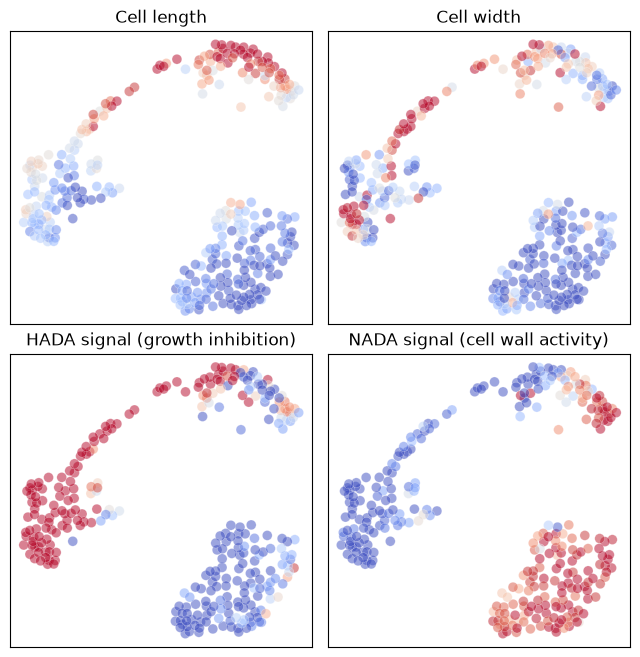

In [947]:
fig,axes=plt.subplots(figsize=(8,8),nrows=2,ncols=2,gridspec_kw={'hspace':0.1,'wspace':0.05})
known_set = anchor[~anchor['Group'].isin(['FtsZ-Ctrl'])]
sns.scatterplot(data=known_set,x='UMAP-1',y='UMAP-2',hue='MEAN_length [µm]',
                palette='coolwarm',alpha=0.5,s=50,ax=axes[0,0],hue_norm=(0,1),
                lw=0.3,legend=False)

sns.scatterplot(data=known_set,x='UMAP-1',y='UMAP-2',hue='MEAN_width_median [µm]',
                palette='coolwarm',alpha=0.5,s=50,ax=axes[0,1],hue_norm=(-0,1),
                lw=0.3,legend=False)

sns.scatterplot(data=known_set,x='UMAP-1',y='UMAP-2',hue='MEAN_C4-C2_diff',
                palette='coolwarm',alpha=0.5,s=50,ax=axes[1,1],hue_norm=(-3,0),
                lw=0.3,legend=False)

sns.scatterplot(data=known_set,x='UMAP-1',y='UMAP-2',hue='MEAN_log2_C3_mean',
                palette='coolwarm',alpha=0.5,s=50,ax=axes[1,0],hue_norm=(0,2),
                lw=0.3,legend=False)

for ax in [axes[0,0],axes[0,1],axes[1,0],axes[1,1]]:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')
axes[0,0].set_title('Cell length')
axes[0,1].set_title('Cell width')
axes[1,0].set_title('HADA signal (growth inhibition)')
axes[1,1].set_title('NADA signal (cell wall activity)')
plt.savefig('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/umap_quad.svg',bbox_inches='tight')

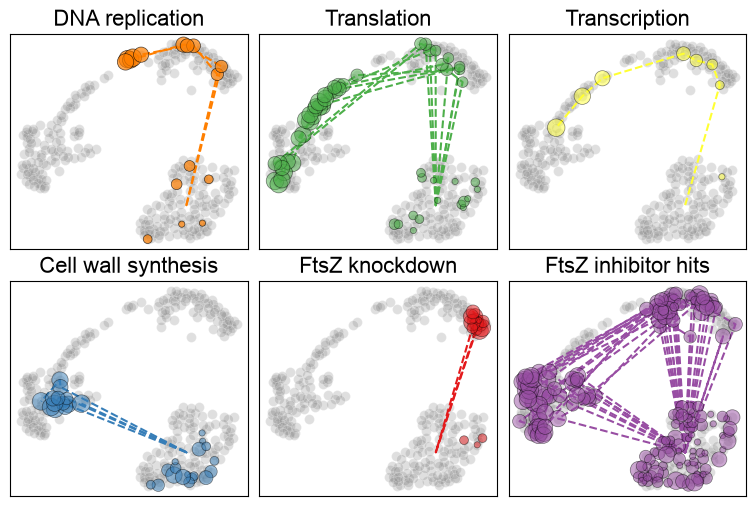

In [1113]:
from scipy.signal import savgol_filter
from matplotlib import colormaps as cm
def plot_savgol(x, y):
    window_length = min(3, len(x))
    if window_length % 2 == 0: window_length -= 1
    if len(x) >= 5: # 保证有足够的数据计算平滑
        x_smooth = savgol_filter(x, window_length=window_length, polyorder=2)
        y_smooth = savgol_filter(y, window_length=window_length, polyorder=2)
        return x_smooth,y_smooth
    else:
        return x,y
    
fig,axes=plt.subplots(figsize=(9.5,6),nrows=2,ncols=3,gridspec_kw={'hspace':0.15,'wspace':0.05})
known_set = anchor[~anchor['Group'].isin(['FtsZ-Ctrl'])].copy().set_index('Sample_UID')
no_response_blob = known_set[(known_set['UMAP-1']>0)&(known_set['UMAP-2']<10)]
no_response_centroid = no_response_blob[['UMAP-1','UMAP-2']].mean()
known_set_start_collapsed = known_set.copy()
no_response = known_set_start_collapsed.loc[no_response_blob.index].copy()
response = known_set_start_collapsed.loc[[x for x in known_set_start_collapsed.index if x not in no_response_blob.index]].copy()
no_response[['UMAP-1','UMAP-2']] =  np.repeat(no_response_centroid.values.reshape(1,-1),128,axis=0)
known_set_start_collapsed= pd.concat([response,no_response])

for ax in [axes[r,c] for r in range(2) for c in range(3)]:
    sns.scatterplot(data=known_set,x='UMAP-1',y='UMAP-2',
                    color='grey',alpha=0.25,s=50,ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')
    
for cpd in ['MXF','CIP']:
    color = cm.get_cmap('Set1')(4)
    subset = known_set_start_collapsed[known_set_start_collapsed['Compound']==cpd].copy().sort_values(by='Fold_mic')
    subset_original = known_set[known_set['Compound']==cpd].copy()
    _x, _y = plot_savgol(subset['UMAP-1'].values,subset['UMAP-2'].values,)
    axes[0,0].plot(_x, _y,ls='--',color=color,)
    axes[0,0].scatter(subset_original['UMAP-1'].values,subset_original['UMAP-2'].values,
                      ec='black',lw=0.5,fc=color,zorder=3,
                      s=(subset_original['log_Fold_mic'].values+4)*20,alpha=0.7)
for cpd in anchor[anchor['Group']=='Translation']['Compound'].unique():
    if cpd == 'Amikacin':
        continue
    color = cm.get_cmap('Set1')(2)
    subset = known_set_start_collapsed[known_set_start_collapsed['Compound']==cpd].copy().sort_values(by='Fold_mic')
    subset_original = known_set[known_set['Compound']==cpd].copy()
    _x, _y = plot_savgol(subset['UMAP-1'].values,subset['UMAP-2'].values)
    axes[0,1].plot(_x, _y,ls='--',color=color)
    axes[0,1].scatter(subset_original['UMAP-1'].values,subset_original['UMAP-2'].values,
                      ec='black',lw=0.5,fc=color,zorder=3,
                      s=(subset_original['log_Fold_mic'].values+4)*20,alpha=0.5)
for cpd in ['RIF']:
    color = cm.get_cmap('Set1')(5)
    subset = known_set_start_collapsed[known_set_start_collapsed['Compound']==cpd].copy().sort_values(by='Fold_mic')
    subset_original = known_set[known_set['Compound']==cpd].copy()
    _x, _y = plot_savgol(subset['UMAP-1'].values,subset['UMAP-2'].values)
    axes[0,2].plot(_x, _y,ls='--',color=color)
    axes[0,2].scatter(subset_original['UMAP-1'].values,subset_original['UMAP-2'].values,
                      ec='black',lw=0.5,fc=color,zorder=3,
                      s=(subset_original['log_Fold_mic'].values+4)*20,alpha=0.5)
    
for cpd in ['INH','SQ109','SBZ-6B','BTZ-043']:
    color = cm.get_cmap('Set1')(1)
    subset = known_set_start_collapsed[known_set_start_collapsed['Compound']==cpd].copy().sort_values(by='Fold_mic')
    subset_original = known_set[known_set['Compound']==cpd].copy()
    _x, _y = plot_savgol(subset['UMAP-1'].values,subset['UMAP-2'].values)
    axes[1,0].plot(_x, _y,ls='--',color=color)
    axes[1,0].scatter(subset_original['UMAP-1'].values,subset_original['UMAP-2'].values,
                      ec='black',lw=0.5,fc=color,zorder=3,
                      s=(subset_original['log_Fold_mic'].values+4)*20,alpha=0.5)
    
for cpd in ['GH161-96hrs-Rep1','GH161-96hrs-Rep2']:
    color = cm.get_cmap('Set1')(0)
    subset = known_set_start_collapsed[known_set_start_collapsed['Compound']==cpd].copy().sort_values(by='Fold_mic')
    subset_original = known_set[known_set['Compound']==cpd].copy()
    _x, _y = plot_savgol(subset['UMAP-1'].values,subset['UMAP-2'].values)
    axes[1,1].plot(_x, _y,ls='--',color=color)
    axes[1,1].scatter(subset_original['UMAP-1'].values,subset_original['UMAP-2'].values,
                      ec='black',lw=0.5,fc=color,zorder=3,
                      s=(subset_original['log_Fold_mic'].values+4)*20,alpha=0.5)

for cpd in anchor[anchor['Group']=='Cell division']['Compound'].unique():
    color = cm.get_cmap('Set1')(3)
    subset = known_set_start_collapsed[known_set_start_collapsed['Compound']==cpd].copy().sort_values(by='Fold_mic')
    subset_original = known_set[known_set['Compound']==cpd].copy()
    _x, _y = plot_savgol(subset['UMAP-1'].values,subset['UMAP-2'].values)
    axes[1,2].plot(_x, _y,ls='--',color=color)
    axes[1,2].scatter(subset_original['UMAP-1'].values,subset_original['UMAP-2'].values,
                      ec='black',lw=0.5,fc=color,zorder=3,
                      s=(subset_original['log_Fold_mic'].values+4)*20,alpha=0.5)
axes[0,0].set_title('DNA replication',fontname='Arial',fontsize=16)
axes[0,1].set_title('Translation',fontname='Arial',fontsize=16)
axes[0,2].set_title('Transcription',fontname='Arial',fontsize=16)
axes[1,0].set_title('Cell wall synthesis',fontname='Arial',fontsize=16)
axes[1,1].set_title('FtsZ knockdown',fontname='Arial',fontsize=16)
axes[1,2].set_title('FtsZ inhibitor hits',fontname='Arial',fontsize=16)
plt.savefig('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/umap_traj.svg',bbox_inches='tight')

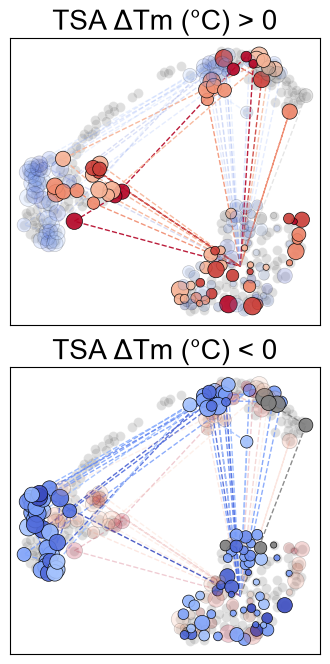

In [1115]:
fig,axes=plt.subplots(figsize=(4,8),nrows=2,gridspec_kw={'hspace':0.15})
for ax in axes:
    sns.scatterplot(data=known_set,x='UMAP-1',y='UMAP-2',color='grey',alpha=0.25,s=50,ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')

cpd_tm_dict = {}
for i,(tm,s) in enumerate(test_compounds[['TSA ΔTm (°C)¹','Src_ID']].values):
    if s!='na' and tm !='—':
        cpd_tm_dict[s] = float(tm.split(' ')[0])
        
for cpd in anchor[anchor['Group']=='Cell division']['Compound'].unique():
    if cpd in cpd_tm_dict:
        tm = cpd_tm_dict[cpd]
        tm_norm = (tm+3)/6
        tm_norm = min(tm_norm,0.999)
        tm_norm = max(tm_norm,0.001)
        color = cm.get_cmap('coolwarm')(tm_norm)
    else:
        color='grey'
    if tm<0:
        alpha1,alpha2 = 0.2, 0.9
    else:
        alpha1,alpha2 = 0.9, 0.2
    if tm_norm ==1:
        print(cpd,color)
    subset = known_set_start_collapsed[known_set_start_collapsed['Compound']==cpd].copy().sort_values(by='Fold_mic')
    subset_original = known_set[known_set['Compound']==cpd].copy()
    _x, _y = plot_savgol(subset['UMAP-1'].values,subset['UMAP-2'].values,)
    axes[0].plot(_x, _y,ls='--',color=color,lw=1,alpha=alpha1)
    axes[1].plot(_x, _y,ls='--',color=color,lw=1,alpha=alpha2)
    axes[0].scatter(subset_original['UMAP-1'].values,subset_original['UMAP-2'].values,
                    ec='black',lw=0.5,fc=color,zorder=3,
                    s=(subset_original['log_Fold_mic'].values+4)*20,alpha=alpha1)
    axes[1].scatter(subset_original['UMAP-1'].values,subset_original['UMAP-2'].values,
                    ec='black',lw=0.5,fc=color,zorder=3,
                    s=(subset_original['log_Fold_mic'].values+4)*20,alpha=alpha2)
axes[0].set_title('TSA ΔTm (°C) > 0',fontname='Arial',fontsize=20)
axes[1].set_title('TSA ΔTm (°C) < 0',fontname='Arial',fontsize=20)
plt.savefig('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/umap_traj_cell_div.svg',bbox_inches='tight')

In [1135]:
cells = mo.pickle_load('/Volumes/ExtremePro/PMM_FTSZ_RAW/20260901_znorm_merged_cells.pk')

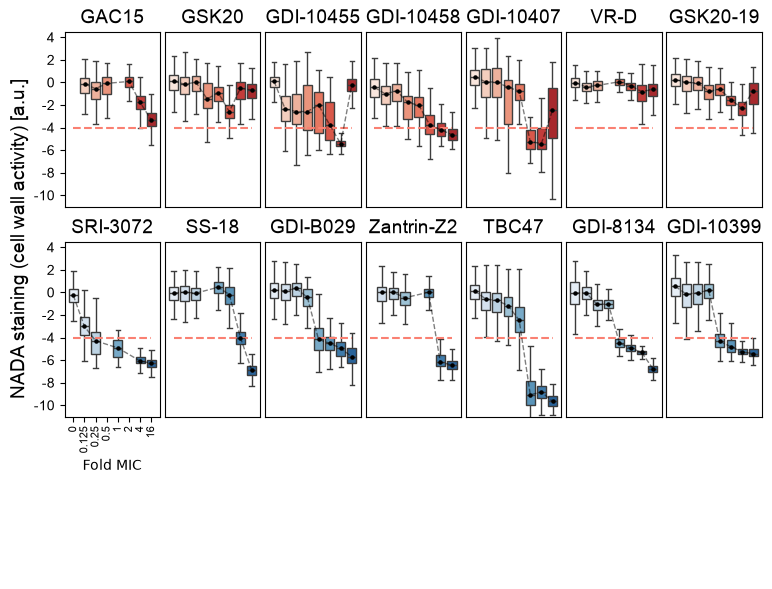

In [1200]:
fig,axes = plt.subplots(figsize=(9,5),nrows=2,ncols=7,gridspec_kw={'wspace':0.05})
destablizers = ['SRI-3072','SS-18','GDI-B029','Zantrin-Z2','TBC47','GDI-8134','GDI-10399']
stablizers = ['GAC15','GSK20','GDI-10455','GDI-10458','GDI-10407','VR-D','GSK20-19']
for i,cpd in enumerate(stablizers):
    subset = cells[cells['Compound']==cpd].copy()
    subset['log_Fold_mic'] = subset['log_Fold_mic'].astype(int)
    order_list = list(range(-3, 5))
    sorted_vals = sorted(subset['log_Fold_mic'].unique())
    sns.boxplot(data=subset,x='log_Fold_mic',y='C4-C2_diff',hue='log_Fold_mic',
                palette='Reds',ax=axes[0,i],legend=False,fliersize=0,order=order_list,hue_norm = (-4,6))
    grouped_v = subset.groupby('log_Fold_mic')['C4-C2_diff'].median()
    axes[0,i].plot(grouped_v.index+3,grouped_v.values,zorder=3,lw=1,color='black',alpha=0.5,ls='--')
    axes[0,i].scatter(grouped_v.index+3,grouped_v.values,zorder=3,lw=1,color='black',s=5,alpha=1)
    axes[0,i].plot(np.arange(8),np.ones(8)*-4,ls='--',color='salmon')
    axes[0,i].set_ylim(-11,4.5)
    axes[0,i].set_xlim(-0.8,7.8)
    axes[0,i].set_xticks([])
    axes[0,i].set_xlabel('')
    axes[0,i].set_ylabel('')
    if i!=0:
        axes[0,i].set_yticks([])
    axes[0,i].set_title(cpd,fontname='Arial',fontsize=14)
for i,cpd in enumerate(destablizers):
    subset = cells[cells['Compound']==cpd].copy()
    subset['log_Fold_mic'] = subset['log_Fold_mic'].astype(int)
    order_list = list(range(-3, 5))
    sorted_vals = sorted(subset['log_Fold_mic'].unique())
    sns.boxplot(data=subset,x='log_Fold_mic',y='C4-C2_diff',hue='log_Fold_mic',
                palette='Blues',ax=axes[1,i],legend=False,fliersize=0,order=order_list,hue_norm = (-4,6))
    grouped_v = subset.groupby('log_Fold_mic')['C4-C2_diff'].median()
    axes[1,i].set_ylim(-11,4.5)
    axes[1,i].plot(grouped_v.index+3,grouped_v.values,zorder=3,lw=1,color='black',alpha=0.5,ls='--')
    axes[1,i].scatter(grouped_v.index+3,grouped_v.values,zorder=3,lw=1,color='black',s=5,alpha=1)
    axes[1,i].plot(np.arange(8),np.ones(8)*-4,ls='--',color='salmon')
    if i!=0:
        axes[1,i].set_yticks([])
        axes[1,i].set_ylabel('')
        axes[1,i].set_xticks([])
        axes[1,i].set_xlabel('')
    axes[1,i].set_title(cpd,fontname='Arial',fontsize=14)
axes[1,0].set_xticks(np.arange(8))
axes[1,0].set_xticklabels([0,0.125,0.25,0.5,1,2,4,16],fontname='Arial',fontsize=8,rotation=90)
axes[1,0].set_xlabel('Fold MIC')
axes[1,0].set_ylabel('   '*12+'NADA staining (cell wall activity) [a.u.]',fontname='Arial',fontsize=14)
for i in range(2):
    axes[i,0].set_yticks(np.arange(-10,5,2))
    axes[i,0].set_yticklabels(np.arange(-10,5,2),fontname='Arial',fontsize=10)

plt.savefig('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/nada_tm_grouped.svg',bbox_inches='tight',transparent=True)

[]

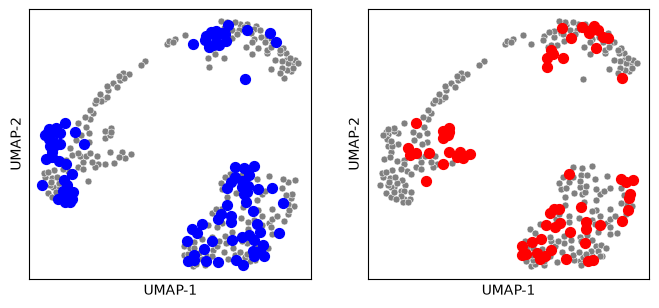

In [948]:
fig,axes=plt.subplots(figsize=(8,3.5),ncols=2)

known_set = anchor[~anchor['Group'].isin(['FtsZ-Ctrl'])]
bottom_left = known_set[(anchor['UMAP-1']<0)&(anchor['UMAP-2']<10)&(anchor['Group']!='FtsZ-Ctrl')]
bottom_right = known_set[(anchor['UMAP-1']>10)&(anchor['UMAP-2']<10)&(anchor['Group']!='FtsZ-Ctrl')]

sns.scatterplot(data=known_set,s=25,
                x='UMAP-1',y='UMAP-2',color='grey',ax=axes[0])
sns.scatterplot(data=known_set,s=25,
                x='UMAP-1',y='UMAP-2',color='grey',ax=axes[1])


for i,(tm,s) in enumerate(test_compounds[['TSA ΔTm (°C)¹','Src_ID']].values):
    if s!='na' and s!='SB-RA-2001':
        if float(tm.split(' ')[0])<0:
            ax=axes[0]
            color='b'
        else:
            ax=axes[1]
            color='r'
        cpd_set = known_set[known_set['Compound']==s].copy().sort_values(by='log_Fold_mic')
        if cpd_set['Group'].values[0] == 'Cell division':
            ax.scatter(cpd_set['UMAP-1'],cpd_set['UMAP-2'],color=color,s=50)
    
axes[0].set_yticks([])
axes[1].set_yticks([])
axes[0].set_xticks([])
axes[1].set_xticks([])
#ax.axis('off')
#plt.savefig('/Users/jzrolling/Desktop/Projects/GHDDI/FtsZ_manuscript/Figures/umap_fold_mic.svg',bbox_inches='tight')

(np.float64(-38.70774631500244),
 np.float64(44.92030506134033),
 np.float64(-37.638885498046875),
 np.float64(41.689903259277344))

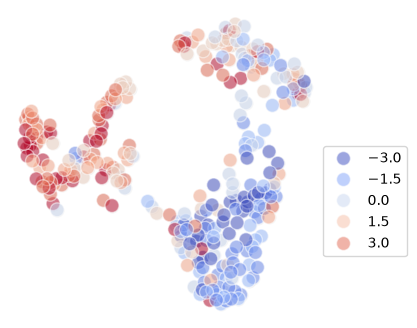

In [838]:
fig=plt.figure(figsize=(4,4))
ax=fig.add_subplot()
sns.scatterplot(data=anchor,x='UMAP-1',y='UMAP-2',color='grey',alpha=0.1,s=100)

sns.scatterplot(data=anchor[anchor['Fold_mic']>=0],x='UMAP-1',y='UMAP-2',hue='log_Fold_mic', 
                palette='coolwarm',s=100,alpha=0.5,legend=True,
                lw=1,
                zorder=5,ax=ax)
ax.legend(loc=(1.01,0.2))
ax.axis('off')

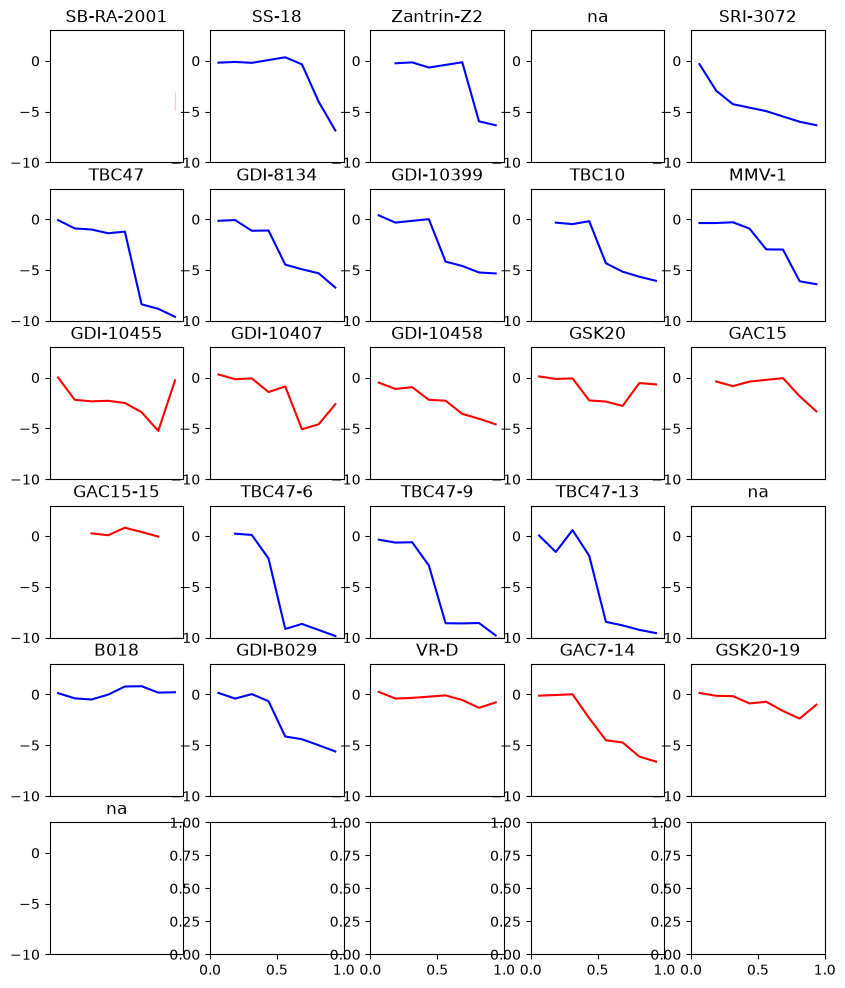

In [657]:
fig,axes = plt.subplots(figsize=(10,12),nrows=6,ncols=5,gridspec_kw={'hspace':0.2})
for i,(tm,s) in enumerate(test_compounds[['TSA ΔTm (°C)¹','Src_ID']].values):
    r,c = i//5, i%5
    ax = axes[r,c]
    feature = 'MEAN_C4-C2_diff'
    ax.set_title(s)
    if s!='na' and s!='SB-RA-2001':
        subset = anchor[anchor['Compound']==s].copy()
        if float(tm.split(' ')[0])<0:
            sns.lineplot(data=subset,x='log_Fold_mic',y=feature,color='b',
                    legend=False,ax=ax)
        else:
            sns.lineplot(data=subset,x='log_Fold_mic',y=feature,color='r',
                    legend=False,ax=ax)
    elif s=='SB-RA-2001':
        sns.lineplot(data=subset,x='log_Fold_mic',y=feature,color='r',
                    legend=False,ax=ax)
    ax.set_xticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_ylim(-10,3)
    ax.set_xlim(-3.5,4.5)



In [434]:
anchor[anchor['Compound']=='GDI-B029']

,Batch,Well,Fold_mic,log_Fold_mic,Compound,Group,MEAN_area,MEAN_eccentricity,MEAN_solidity,MEAN_major_axis_length,...,Q3_C4_kurtosis,Q3_C4_skewness,Q3_C4-C2_diff,Group_count,Sample_UID,PC1,PC2,UMAP-1,UMAP-2,Outgrowth


In [435]:
anchor[(anchor['UMAP-1']<-10)&(anchor['UMAP-2']>5)]

,Batch,Well,Fold_mic,log_Fold_mic,Compound,Group,MEAN_area,MEAN_eccentricity,MEAN_solidity,MEAN_major_axis_length,...,Q3_C4_kurtosis,Q3_C4_skewness,Q3_C4-C2_diff,Group_count,Sample_UID,PC1,PC2,UMAP-1,UMAP-2,Outgrowth
0,BCG_FtsZ_HT_PC_4daysinduction_Plate02_20250626,A01,16.0,4.0,GH161-96hrs-Rep1,FtsZ-KD,0.622463,-0.136165,-0.091197,0.550146,...,0.602356,0.860151,0.963253,2736.0,BCG_FtsZ_HT_PC_4daysinduction_Plate02_20250626...,9.157243,-5.860205,-15.938867,5.339697,-0.381050
2,BCG_FtsZ_HT_PC_4daysinduction_Plate02_20250626,A03,8.0,3.0,GH161-96hrs-Rep1,FtsZ-KD,0.857682,-0.180365,-0.318635,0.789681,...,0.878257,1.277757,0.565572,4005.0,BCG_FtsZ_HT_PC_4daysinduction_Plate02_20250626...,20.786140,-7.498809,-17.484886,6.216170,-1.609633
4,BCG_FtsZ_HT_PC_4daysinduction_Plate02_20250626,A05,4.0,2.0,GH161-96hrs-Rep1,FtsZ-KD,1.004457,0.049103,-0.430016,1.003498,...,0.691917,1.172673,0.445113,2313.0,BCG_FtsZ_HT_PC_4daysinduction_Plate02_20250626...,22.425988,-5.598158,-18.707413,6.928771,-1.664577
8,BCG_FtsZ_HT_PC_4daysinduction_Plate02_20250626,B01,16.0,4.0,GH161-96hrs-Rep2,FtsZ-KD,0.480987,-0.146260,-0.151191,0.494063,...,0.729316,0.987071,0.939299,7663.0,BCG_FtsZ_HT_PC_4daysinduction_Plate02_20250626...,10.223936,-6.818069,-16.509607,5.480459,-0.843011
10,BCG_FtsZ_HT_PC_4daysinduction_Plate02_20250626,B03,8.0,3.0,GH161-96hrs-Rep2,FtsZ-KD,1.001102,-0.161305,-0.258277,0.793281,...,0.664113,1.230546,0.630346,1786.0,BCG_FtsZ_HT_PC_4daysinduction_Plate02_20250626...,18.775859,-6.106993,-17.529724,5.561949,-1.398574
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,BCG_FtsZ_HT_Plate10_Batch03_20250529,A04,0.5,-1.0,Gentamycin,Translation,1.716057,0.194841,-0.517410,1.556915,...,1.978470,2.005625,-2.310182,11093.0,BCG_FtsZ_HT_Plate10_Batch03_20250529_A04,24.960381,3.360686,-17.533350,13.512305,-2.362011
306,BCG_FtsZ_HT_Plate01_Batch01_20250519,B02,1.0,0.0,RIF,Transcription,1.419151,0.355835,-0.468334,1.501738,...,3.147734,2.730063,-0.350305,3224.0,BCG_FtsZ_HT_Plate01_Batch01_20250519_B02,10.801067,4.094386,-20.822863,14.496955,-0.337483
308,BCG_FtsZ_HT_Plate01_Batch01_20250519,B04,0.5,-1.0,RIF,Transcription,1.091185,0.163471,-0.346252,1.061405,...,1.057282,1.545399,0.300071,5872.0,BCG_FtsZ_HT_Plate01_Batch01_20250519_B04,8.739360,0.238084,-20.662409,11.749287,0.107761
309,BCG_FtsZ_HT_Plate01_Batch01_20250519,B05,4.0,2.0,RIF,Transcription,1.250834,0.189299,-0.303559,1.202064,...,4.474515,3.210289,-2.578325,3632.0,BCG_FtsZ_HT_Plate01_Batch01_20250519_B05,5.565727,6.046063,-16.703232,18.163128,-3.281208


/Users/jzrolling/miniconda3/envs/tensorflow_env/lib/python3.11/site-packages/umap/umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
/Users/jzrolling/miniconda3/envs/tensorflow_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


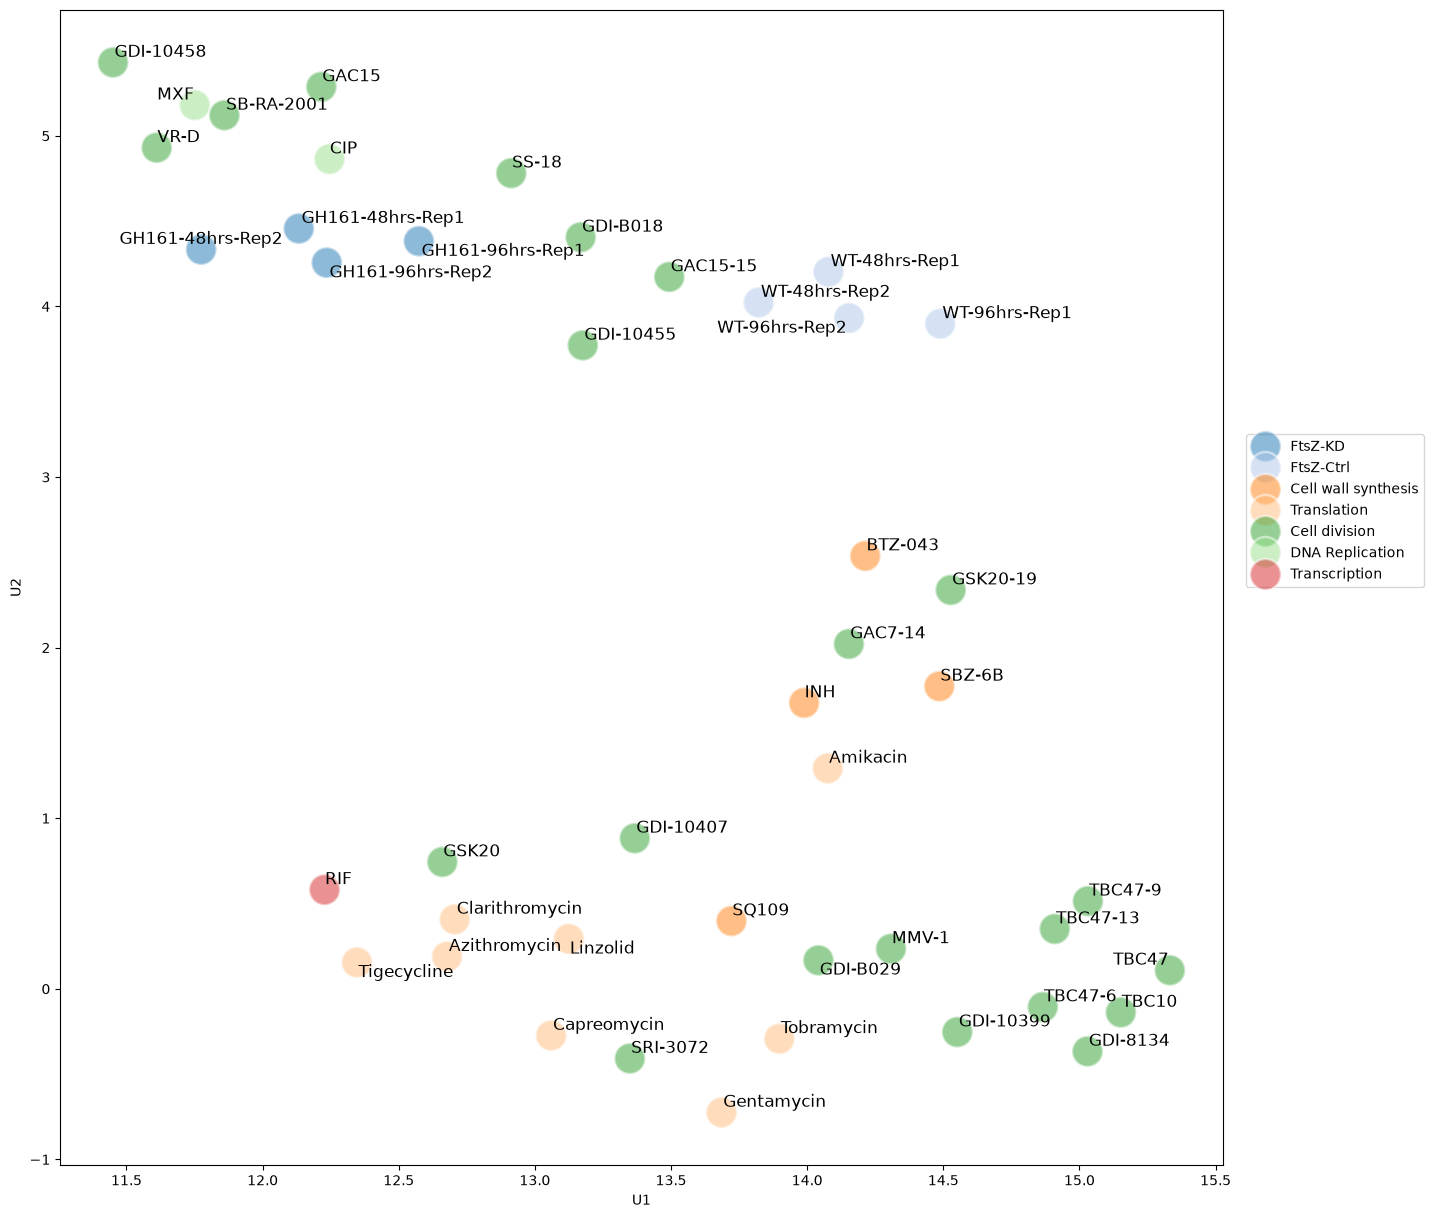

In [204]:
from sklearn.impute import KNNImputer
import matplotlib.patches as mpatches
from adjustText import adjust_text

n_umap_dim=2
n_compounds = len(anchor['Compound'].unique())
umap_cols = [f'UMAP-{x}' for x in range(1,n_umap_dim+1)]
umap_mat = np.zeros((n_umap_dim,n_compounds,8))
umap_mat += np.nan
conc2id = {x:i for i,x in enumerate([0,0.25,0.5,1,2,4,8,16])}
compound_list = []
group_list = []
for i,drug in enumerate(anchor['Compound'].unique()):
    subset = anchor[(anchor['Compound']==drug)&(anchor['Fold_mic']>=0.)].sort_values(by='Fold_mic')
    if len(subset['Batch'].unique())>1:
        selected_batch = subset.groupby('Batch').count().sort_values(by='Group').index[-1]
        subset = subset[subset['Batch']==selected_batch].copy()
    drug_coords = subset[umap_cols].values
    drug_conc = subset['Fold_mic'].values
    for j,c in enumerate(drug_conc):
        umap_mat[:,i,conc2id[c]] = drug_coords[j]
    compound_list.append(drug)
    group_list.append(subset['Group'].values[0])

# run knn imputation to fill missing values
knn_imputer = KNNImputer()
imputed = np.array([knn_imputer.fit_transform(x) for x in umap_mat])

# run dtw
dist_mat = np.zeros((n_compounds,n_compounds))

for i in range(n_compounds-1):
    for j in range(i+1,n_compounds):
        traj_i = imputed[:,i,:].T # Concentrations x Features
        traj_j = imputed[:,j,:].T
        alignment = dtw(traj_i, traj_j, 
                        dist_method='euclidean')
        dist_mat[i, j] = alignment.distance
        dist_mat[j, i] = alignment.distance # 因为距离矩阵是对称的

mapper = UMAP(
    n_neighbors=15,      # Controls how UMAP balances local vs. global structure.
    min_dist=0.1,        # Controls how tightly points are packed together.
    n_components=2,      # We want a 2D embedding.
    metric='precomputed',
    spread=1,
    random_state=11      # For reproducible results.
)

# Run the UMAP algorithm on the distance matrix to get the 2D embedding.
embedding = mapper.fit_transform(dist_mat)

reembedded = pd.DataFrame(embedding,columns=['U1','U2'])
reembedded['Compound'] = compound_list
reembedded['Group'] = group_list
reembedded['Compound_group'] = group_list

fig=plt.figure(figsize=(15,15))
ax = fig.add_subplot()
sns.scatterplot(data=reembedded,x='U1',y='U2',
                hue='Compound_group',
                palette='tab20',s=500,alpha=0.5)

texts = []
for d1,d2,drug in reembedded[['U1','U2','Compound']].values:
    texts.append(ax.text(d1,d2,drug,fontsize=12,ha='center',va='center',zorder=6))
adjust_text(texts)
plt.legend(loc=(1.02,0.5))
#plt.savefig(outfolder+'20250916_BCG_BCP_DTW.png',dpi=350,bbox_inches='tight')

In [780]:
merged_grouped[merged_grouped['Compound']=='INH']

,Batch,Well,Fold_mic,log_Fold_mic,Compound,Group,MEAN_area,MEAN_eccentricity,MEAN_solidity,MEAN_major_axis_length,...,Q3_C2_skewness,Q3_C3_CV,Q3_C3_kurtosis,Q3_C3_skewness,Q3_C4_CV,Q3_C4_kurtosis,Q3_C4_skewness,Q3_C4-C2_diff,Group_count,Sample_UID
87,BCG_FtsZ_HT_Plate01_Batch01_20250519,A01,16.00,4.0,INH,Cell wall synthesis,0.093606,0.260627,0.250113,0.118905,...,1.476498,0.292119,-0.099066,-0.626487,3.993997,0.862404,1.737429,-2.414837,6380.0,BCG_FtsZ_HT_Plate01_Batch01_20250519_A01
88,BCG_FtsZ_HT_Plate01_Batch01_20250519,A02,1.00,0.0,INH,Cell wall synthesis,-0.259396,-0.037312,0.103050,-0.224938,...,0.639168,0.136553,0.035828,0.650652,0.043516,0.448240,0.682126,0.639709,7988.0,BCG_FtsZ_HT_Plate01_Batch01_20250519_A02
89,BCG_FtsZ_HT_Plate01_Batch01_20250519,A03,8.00,3.0,INH,Cell wall synthesis,0.130206,0.216643,0.261641,0.122535,...,1.648257,2.117262,0.603362,-0.255208,4.178151,0.926133,1.781553,-2.414432,5657.0,BCG_FtsZ_HT_Plate01_Batch01_20250519_A03
90,BCG_FtsZ_HT_Plate01_Batch01_20250519,A04,0.50,-1.0,INH,Cell wall synthesis,-0.260637,0.068764,0.044834,-0.164027,...,0.256851,-0.184421,-0.122545,0.250600,0.382363,0.517573,0.749571,0.704413,12185.0,BCG_FtsZ_HT_Plate01_Batch01_20250519_A04
91,BCG_FtsZ_HT_Plate01_Batch01_20250519,A05,4.00,2.0,INH,Cell wall synthesis,0.028059,0.179603,0.283840,0.016868,...,1.350940,1.883488,0.155608,-0.351941,3.598062,0.709329,1.592808,-2.439897,6912.0,BCG_FtsZ_HT_Plate01_Batch01_20250519_A05
92,BCG_FtsZ_HT_Plate01_Batch01_20250519,A06,0.25,-2.0,INH,Cell wall synthesis,-0.238328,0.027763,0.039769,-0.166817,...,0.291795,-0.204128,-0.079053,0.334786,0.186006,0.536951,0.744694,0.954635,11844.0,BCG_FtsZ_HT_Plate01_Batch01_20250519_A06
93,BCG_FtsZ_HT_Plate01_Batch01_20250519,A07,2.00,1.0,INH,Cell wall synthesis,-0.018241,0.036714,0.339228,-0.113020,...,1.336071,1.519765,-0.334126,-0.181086,3.641342,0.485735,1.459256,-2.334994,6276.0,BCG_FtsZ_HT_Plate01_Batch01_20250519_A07
94,BCG_FtsZ_HT_Plate01_Batch01_20250519,A08,0.00,-3.0,INH,Cell wall synthesis,-0.026335,0.001729,0.000444,-0.008577,...,0.481587,0.005503,-0.058219,0.484067,0.453651,0.356650,0.635832,0.615881,4487.0,BCG_FtsZ_HT_Plate01_Batch01_20250519_A08
201,BCG_FtsZ_HT_Plate02_Batch04_20250519,A01,16.00,4.0,INH,Cell wall synthesis,0.551606,0.167802,0.142591,0.345151,...,1.789556,0.300936,-0.190545,-0.499224,4.132637,0.902728,1.856937,-2.774739,3170.0,BCG_FtsZ_HT_Plate02_Batch04_20250519_A01
202,BCG_FtsZ_HT_Plate02_Batch04_20250519,A02,1.00,0.0,INH,Cell wall synthesis,-0.148708,-0.154750,0.089148,-0.186098,...,0.597406,-0.177472,0.037173,0.673661,-0.757718,0.397929,0.838407,1.918504,23318.0,BCG_FtsZ_HT_Plate02_Batch04_20250519_A02
